# Recovering an optical Mueller operator from intensity

This is a nonspatial physical inverse problem: all 16 entries of a real optical transfer matrix are recovered from an angular intensity scan. The bound data are **author-synthetic**, generated by executing the unchanged published author's physical example before extracting local code. They are not experimental camera measurements.

## 1. Observation, acquisition and true-reference role

Two calibrated quarter-wave retarders rotate at a 5:1 angular ratio between fixed horizontal polarizers. Unit unpolarized incident light is detected as a single intensity sequence. The complete bound case has 24 endpoint-inclusive generator angles from 0 to π. We also preserve the author's separate 16-angle 0 to 2π acquisition, which demonstrates aliasing. No angle is removed from the benchmark to simplify inversion.

The hidden synthetic sample matrix is actual simulation truth from the original program. It is loaded below only after the fresh reconstruction for maintainer truth comparisons. It is never an input to the inverse or to its calibration.

Active Python: D:\yan1\agent\AutoSkill\imaging-101-maintainer\research-runtime\Scripts\python.exe NumPy: 2.4.6
Complete bound acquisition: (24,) (24,)


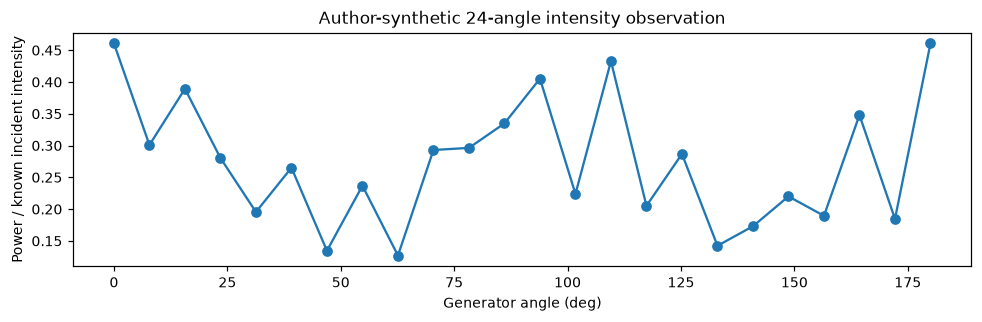

In [1]:
from pathlib import Path
import sys,time,json,importlib.util
import numpy as np
import matplotlib.pyplot as plt
root=Path.cwd()
if not (root/'src').is_dir():root=root.parent
sys.path.insert(0,str(root))
from src.main import run
from src.solvers import reconstruct
from src.physics_model import forward,coherency_matrix
from src.visualization import matrix_comparison,scan_comparison,rank_comparison
plt.rcParams.update({'figure.dpi':110,'font.size':9})
with np.load(root/'data/raw_data.npz',allow_pickle=False) as z:angles=z['angles'][0];power=z['power'][0]
print('Active Python:',sys.executable,'NumPy:',np.__version__)
print('Complete bound acquisition:',angles.shape,power.shape)
fig,ax=plt.subplots(figsize=(9,3));ax.plot(np.rad2deg(angles),power,'o-');ax.set(xlabel='Generator angle (deg)',ylabel='Power / known incident intensity',title='Author-synthetic 24-angle intensity observation');fig.tight_layout();plt.show()

## 2. Optical acquisition and local inverse

The unknown sample maps Stokes columns by $s_{out}=Ms_{in}$, inI,Q,U,Vorder. Circular polarization uses $V=2\mathrm{Im}(E_xE_y^*)$, where the star is complex conjugation. Known generator optics have first column $g_n$ and known analyzer optics have first row $a_n^T$ at angle index n. The intensity is

$$
p_n=a_n^TMg_n=\sum_{i,j}a_{n,i}M_{ij}g_{n,j}.
$$

Here p is relative detector intensity; i,jindex output/input Stokes components. Explicit local polarizer/retarder matrices preserve handedness and the physical half-transmission of an ideal polarizer. Their row-major outer products form the 24×16 design W. The selected inverse is $\hat m=V_s\Sigma^+U_s^Tp$, where $m$ is the row-major sample matrix, and $U_s,\Sigma,V_s$ are the SVD factors of W. Singular values no greater than 1e-15 of the largest are discarded. There is no target-family constraint, learned network, scale fit, normalization by the unknown sample, or iterative substitution.

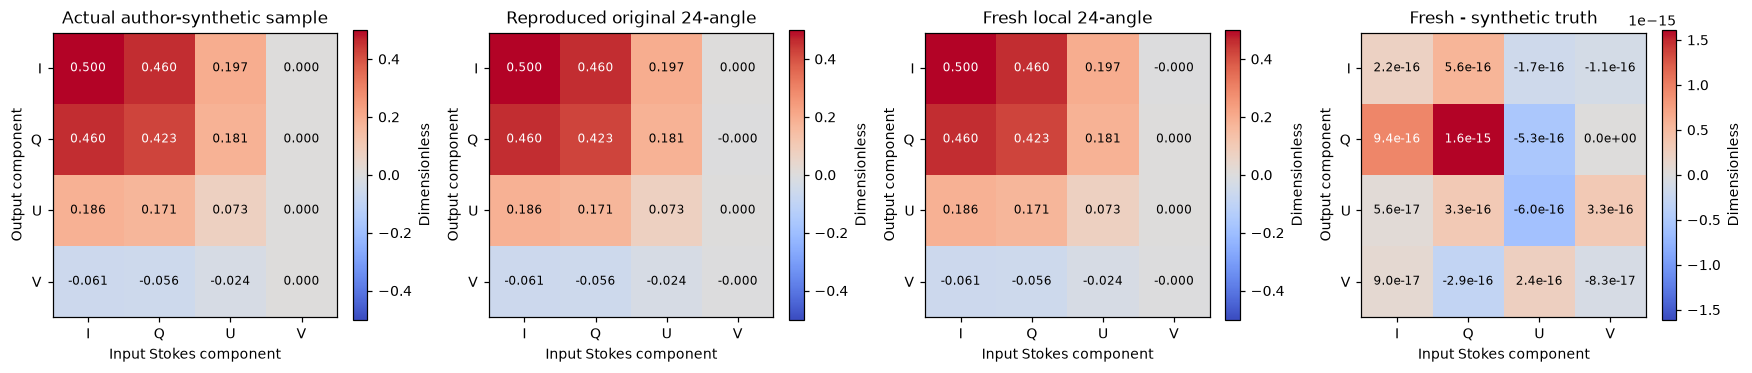

Fresh complete inverse runtime (s): 0.0011563000152818859
Native24 / fresh retained rank: 16 16
Fresh24 matrix condition: 18.1044397903862


In [2]:
started=time.perf_counter()
fresh,d24,runtime=run(root/'data/raw_data.npz',root/'output/reconstruction.npz')
with np.load(root/'evaluation/ground_truth.npz',allow_pickle=False) as z:truth=z['reconstruction'][0]
with np.load(root/'notebooks/reference_outputs/upstream_24.npz',allow_pickle=False) as z:original24={k:z[k].copy() for k in z.files}
with np.load(root/'notebooks/reference_outputs/upstream_16.npz',allow_pickle=False) as z:original16={k:z[k].copy() for k in z.files}
fresh16,d16=reconstruct(original16['angles'],original16['power'])
matrix_comparison(truth,original24['reconstruction'],fresh['reconstruction'][0]);plt.show()
print('Fresh complete inverse runtime (s):',runtime)
print('Native24 / fresh retained rank:',np.linalg.matrix_rank(original24['design']),d24['rank'])
print('Fresh24 matrix condition:',d24['condition'])

## 3. Original comparison and all16element metrics

Both native conditions are reconstructed afresh with the cleaned modules. Archived original reconstructions are shown only as reproduced upstream comparisons. The original author's percent-by-element comparison divides by genuine zero entries and prints undefined values; we preserve those warnings privately and replace that reporting with full-matrix cosine NCC, dynamic-range NRMSE and absolute element error. This changes reporting without altering either original acquisition or its inverse.

The16-angle design has only 12 identifiable directions. It can fit the observed powers while missing the actual matrix. The24-angle acquisition has full rank 16 and resolves those directions. A continuous-angle forward comparison makes the information loss visible between the originally acquired angles.

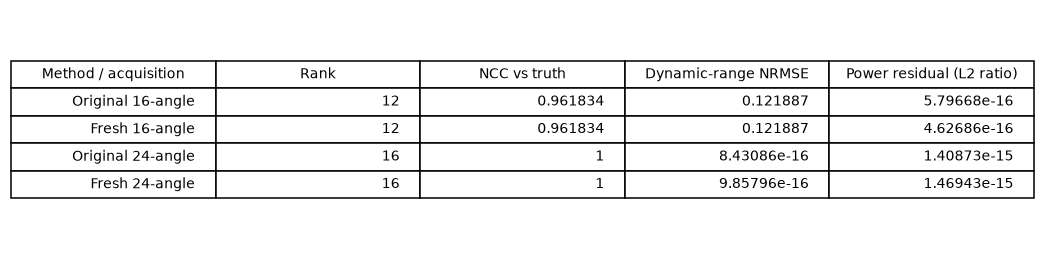

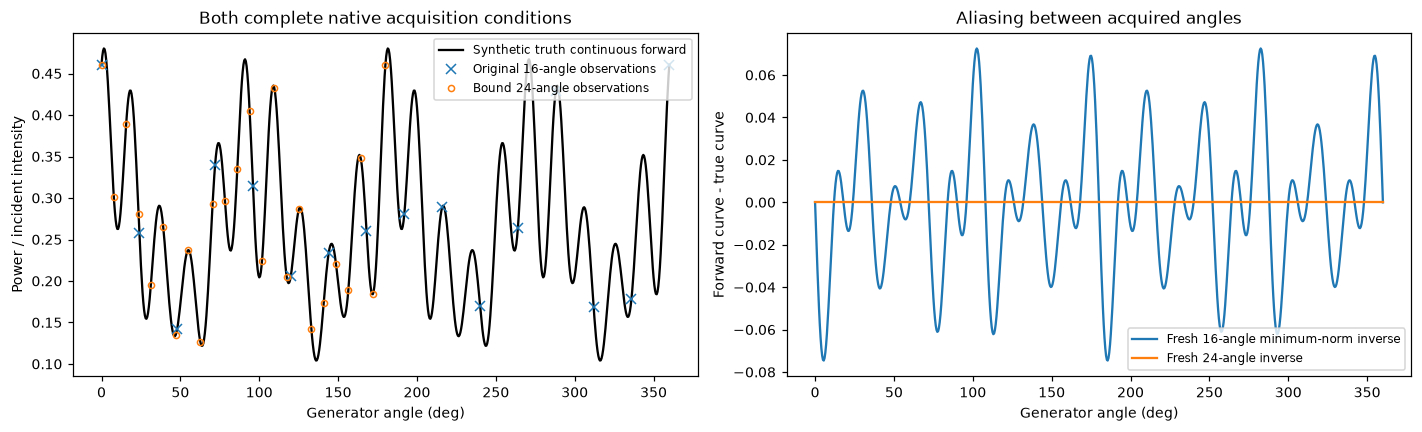

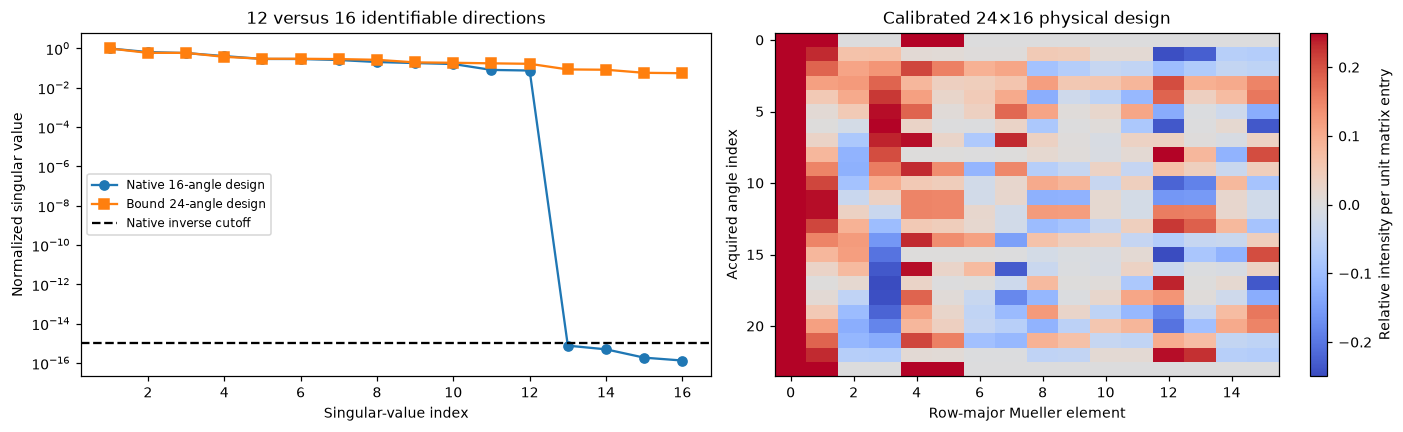

{
  "status": "pass",
  "passed": true,
  "metrics": {
    "ncc_vs_truth": 1.0,
    "nrmse_vs_truth": 9.857961103437454e-16,
    "observation_relative_l2": 1.469426955307392e-15
  },
  "thresholds": {
    "ncc_vs_truth": {
      "comparison": ">=",
      "boundary": 0.999999999
    },
    "nrmse_vs_truth": {
      "comparison": "<=",
      "boundary": 1e-10
    },
    "observation_relative_l2": {
      "comparison": "<=",
      "boundary": 1e-10
    }
  },
  "errors": []
}


In [3]:
spec=importlib.util.spec_from_file_location('standalone_judge',root/'evaluation/judge.py');judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
report,exitcode=judge.evaluate(root/'output/reconstruction.npz');assert exitcode==0,report
comparisons=[]
for label,mat,ang,obs,rank in [('Original 16-angle',original16['reconstruction'],original16['angles'],original16['power'],12),('Fresh 16-angle',fresh16['reconstruction'][0],original16['angles'],original16['power'],d16['rank']),('Original 24-angle',original24['reconstruction'],angles,power,16),('Fresh 24-angle',fresh['reconstruction'][0],angles,power,d24['rank'])]:
    metrics=judge.score_arrays(mat[None],truth[None],ang,obs)
    comparisons.append({'method':label,'rank':rank,**metrics})
fig,ax=plt.subplots(figsize=(12,2.8));ax.axis('off')
table=ax.table(cellText=[[r['method'],r['rank']]+[f'{r[k]:.6g}' for k in ['ncc_vs_truth','nrmse_vs_truth','observation_relative_l2']] for r in comparisons],colLabels=['Method / acquisition','Rank','NCC vs truth','Dynamic-range NRMSE','Power residual (L2 ratio)'],loc='center')
table.auto_set_font_size(False);table.set_fontsize(9);table.scale(1,1.5);plt.show()
dense=np.linspace(0,2*np.pi,721)
scan_comparison(original16['angles'],original16['power'],angles,power,dense,forward(truth,dense),forward(fresh16['reconstruction'][0],dense),forward(fresh['reconstruction'][0],dense));plt.show()
rank_comparison(d16['design'],d24['design'],d16['singular_values'],d24['singular_values']);plt.show()
print(json.dumps(report,indent=2))

## 4. Residuals, null directions and physical validity

The following residual uses all 24 bound measurements and the absolute known intensity calibration. The null direction comes from a fresh SVD of the native16-angle design. Adding it to a matrix changes that underdetermined operator without changing its16acquired intensities; the 24-angle experiment can detect that same change.

Coherency is an independent physical diagnostic. A physically realizable Mueller matrix has a positive semidefinite coherency matrix. The noiseless true sample and recovered matrix satisfy this to floating-point precision. This check is not imposed as a projection, and does not replace truth or measurement agreement.

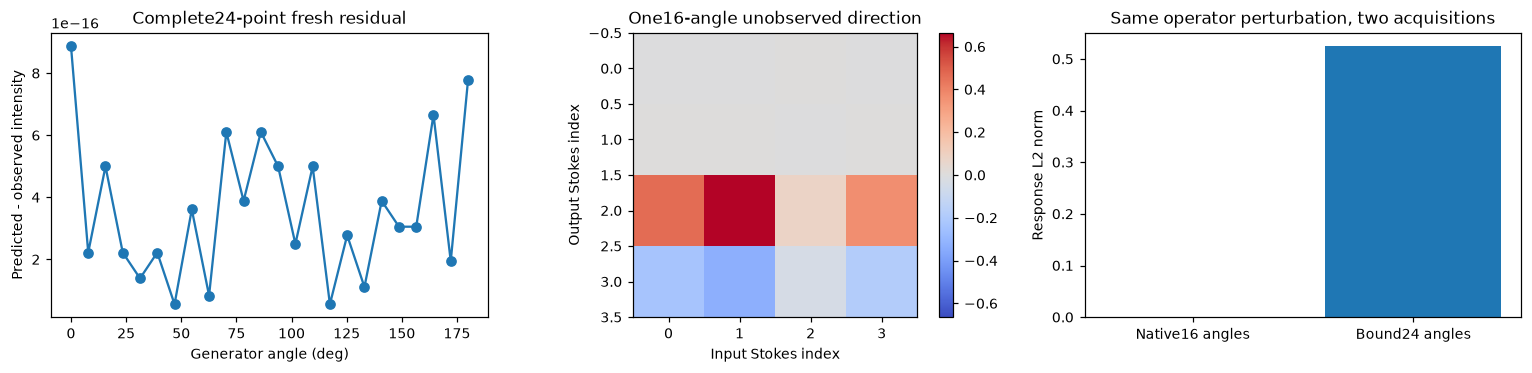

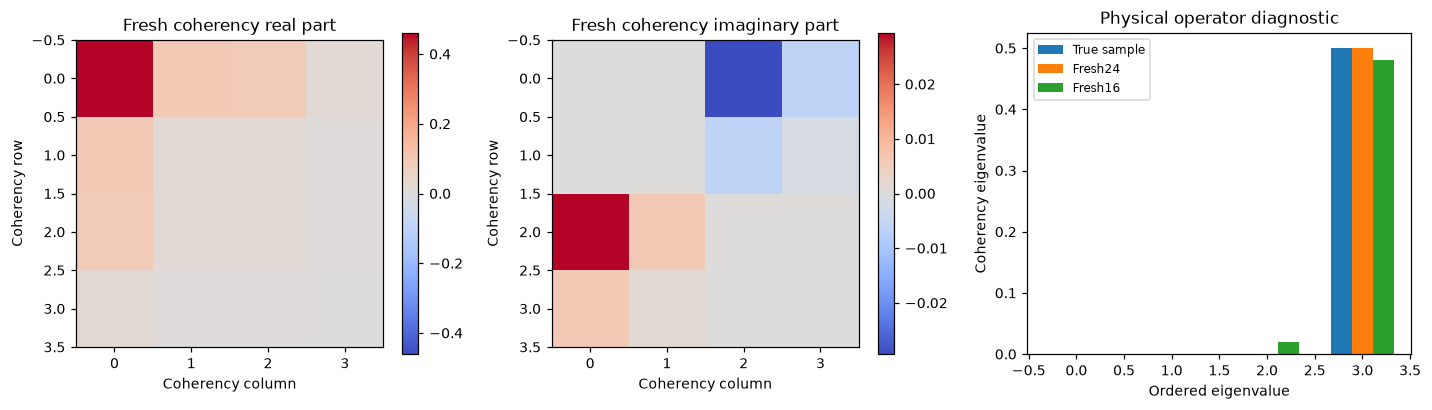

Hermiticity discrepancy: 0.0
Coherency eigenvalues, fresh24: [-4.87208362e-16 -1.48077421e-16  1.76019235e-16  5.00000000e-01]


In [4]:
u,s,vh=np.linalg.svd(d16['design'],full_matrices=False);null=vh[d16['rank']].reshape(4,4)
fig,ax=plt.subplots(1,3,figsize=(14,3.6))
ax[0].plot(np.rad2deg(angles),d24['residual'],'o-');ax[0].set(xlabel='Generator angle (deg)',ylabel='Predicted - observed intensity',title='Complete24-point fresh residual')
limit=max(float(np.max(np.abs(null))),1e-18);im=ax[1].imshow(null,cmap='coolwarm',vmin=-limit,vmax=limit);ax[1].set(xlabel='Input Stokes index',ylabel='Output Stokes index',title='One16-angle unobserved direction');fig.colorbar(im,ax=ax[1])
ax[2].bar(['Native16 angles','Bound24 angles'],[np.linalg.norm(forward(null,original16['angles'])),np.linalg.norm(forward(null,angles))]);ax[2].set(ylabel='Response L2 norm',title='Same operator perturbation, two acquisitions')
fig.tight_layout();plt.show()
h=coherency_matrix(fresh['reconstruction'][0]);htrue=coherency_matrix(truth);h16=coherency_matrix(fresh16['reconstruction'][0])
fig,ax=plt.subplots(1,3,figsize=(13,3.8))
for a,z,label in zip(ax[:2],[h.real,h.imag],['Fresh coherency real part','Fresh coherency imaginary part']):
    limit=max(float(np.max(np.abs(z))),1e-18);im=a.imshow(z,cmap='coolwarm',vmin=-limit,vmax=limit);a.set(title=label,xlabel='Coherency column',ylabel='Coherency row');fig.colorbar(im,ax=a)
eig_true=np.linalg.eigvalsh(htrue);eig_fresh=np.linalg.eigvalsh(h);eig16=np.linalg.eigvalsh(h16)
x=np.arange(4);ax[2].bar(x-.22,eig_true,width=.22,label='True sample');ax[2].bar(x,eig_fresh,width=.22,label='Fresh24');ax[2].bar(x+.22,eig16,width=.22,label='Fresh16');ax[2].set(xlabel='Ordered eigenvalue',ylabel='Coherency eigenvalue',title='Physical operator diagnostic');ax[2].legend(fontsize=8)
fig.tight_layout();plt.show()
print('Hermiticity discrepancy:',np.max(abs(h-h.conj().T)))
print('Coherency eigenvalues, fresh24:',eig_fresh)

## 5. Sampling and calibration ablations

Subsets below are selected from the full bound 24-angle schedule solely to examine identifiability and acquisition cost. They do not replace the complete task. Their angular schedules differ from the author's separate 16-angle 0 to 2π condition, so the two experiments must not be conflated.

Retardance perturbations deliberately use an incorrect generator calibration in the inverse while keeping the measured data fixed. The nominal quarter-wave case is recomputed as well. This exposes sensitivity to known-optics errors without secretly deriving a calibration from the true sample.

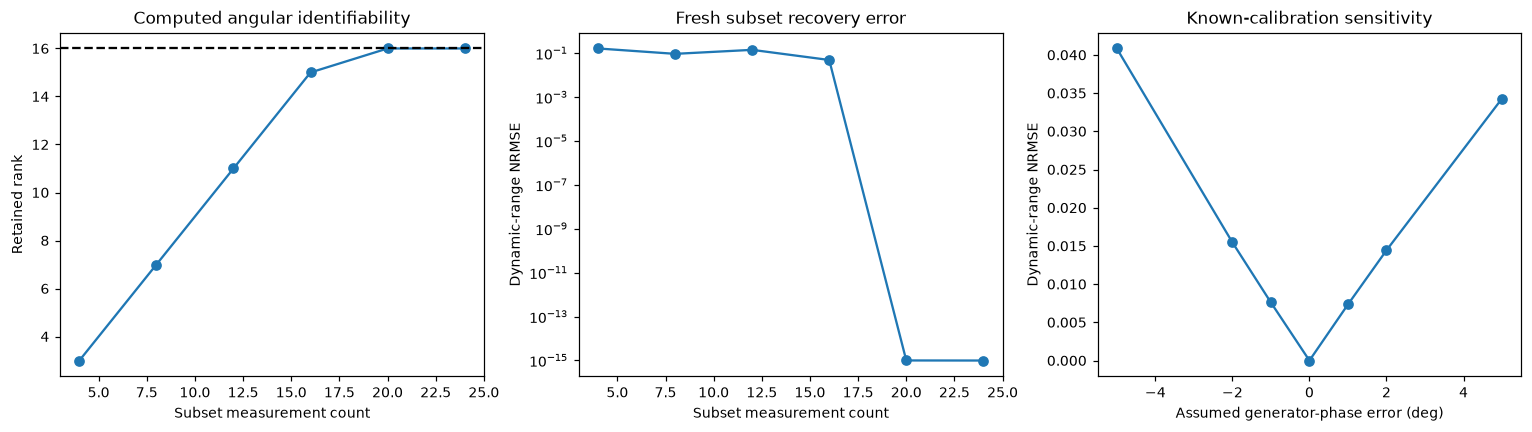

Subset acquisitions: [{'count': 4, 'rank': 3, 'ncc_vs_truth': 0.9287539320029674, 'nrmse_vs_truth': 0.16512326621996143, 'observation_relative_l2': 3.6614071477163225e-16}, {'count': 8, 'rank': 7, 'ncc_vs_truth': 0.977508597690755, 'nrmse_vs_truth': 0.09394136471541495, 'observation_relative_l2': 2.589905920914053e-16}, {'count': 12, 'rank': 11, 'ncc_vs_truth': 0.9471954212254283, 'nrmse_vs_truth': 0.14283346404291755, 'observation_relative_l2': 4.3398598284637833e-16}, {'count': 16, 'rank': 15, 'ncc_vs_truth': 0.9938539663966323, 'nrmse_vs_truth': 0.04930983466665477, 'observation_relative_l2': 1.976193788674764e-16}, {'count': 20, 'rank': 16, 'ncc_vs_truth': 1.0, 'nrmse_vs_truth': 9.945518819997111e-16, 'observation_relative_l2': 1.238685783734103e-15}, {'count': 24, 'rank': 16, 'ncc_vs_truth': 1.0, 'nrmse_vs_truth': 9.857961103437454e-16, 'observation_relative_l2': 1.469426955307392e-15}]
Calibration perturbations: [{'phase_error_deg': -5.0, 'ncc_vs_truth': 0.9958614119736293, 'nrms

In [5]:
sampling=[]
for count in [4,8,12,16,20,24]:
    index=np.unique(np.round(np.linspace(0,23,count)).astype(int))
    out,dd=reconstruct(angles[index],power[index])
    metrics=judge.score_arrays(out['reconstruction'],truth[None],angles[index],power[index])
    sampling.append(dict(count=int(len(index)),rank=dd['rank'],**metrics))
calibration=[]
for delta_deg in [-5.,-2.,-1.,0.,1.,2.,5.]:
    out,dd=reconstruct(angles,power,psg_retardance=np.pi/2+np.deg2rad(delta_deg))
    metrics=judge.score_arrays(out['reconstruction'],truth[None],angles,power)
    calibration.append(dict(phase_error_deg=delta_deg,**metrics))
fig,ax=plt.subplots(1,3,figsize=(14,4))
ax[0].plot([r['count'] for r in sampling],[r['rank'] for r in sampling],'o-');ax[0].axhline(16,color='k',ls='--');ax[0].set(xlabel='Subset measurement count',ylabel='Retained rank',title='Computed angular identifiability')
ax[1].semilogy([r['count'] for r in sampling],[r['nrmse_vs_truth'] for r in sampling],'o-');ax[1].set(xlabel='Subset measurement count',ylabel='Dynamic-range NRMSE',title='Fresh subset recovery error')
ax[2].plot([r['phase_error_deg'] for r in calibration],[r['nrmse_vs_truth'] for r in calibration],'o-');ax[2].set(xlabel='Assumed generator-phase error (deg)',ylabel='Dynamic-range NRMSE',title='Known-calibration sensitivity')
fig.tight_layout();plt.show()
print('Subset acquisitions:',sampling)
print('Calibration perturbations:',calibration)

## 6. Noise robustness and interpretation

The bound author case is noiseless. The following 256 fresh inversions add controlled Gaussian intensity perturbations, using 64 replicates at each specified RMS-relative level. They are sensitivity experiments, not experimental data or claims of measured instrument uncertainty. The zero-noise group is computed, not inserted as a zero placeholder.

The complete24-angle acquisition recovers the true simulated full transfer operator at numerical precision. Its original16-angle counterpart illustrates a physical acquisition failure: excellent intensity fit can coexist with lost operator information. Matrix and forward metrics, acquisition rank, independent Jones/Stokes physics and calibration/noise sensitivity together explain the result. Physical validation does not convert these author-synthetic observations into laboratory measurements.

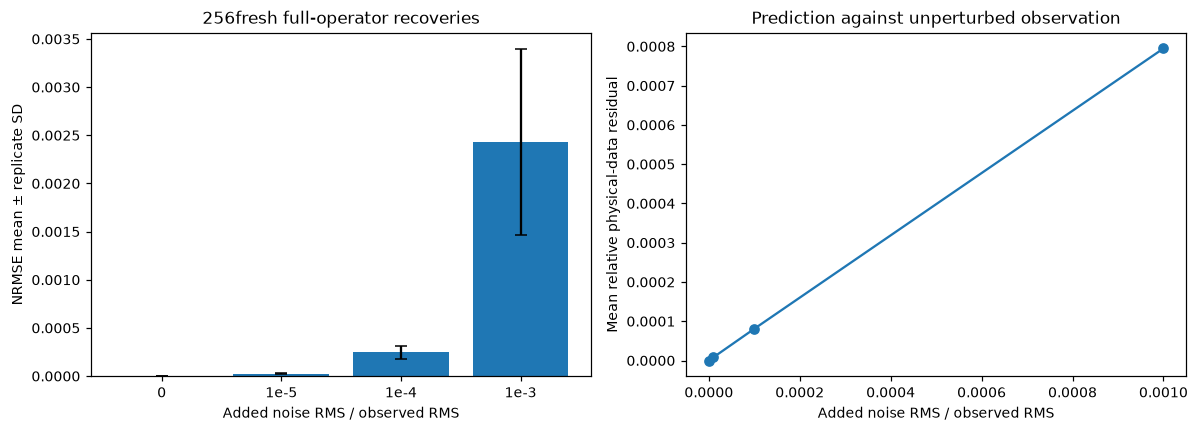

Fresh benchmark and every comparison/robustness result above are computed.
Notebook compute seconds: 1.4548548000166193


In [6]:
rng=np.random.default_rng(20261027);noise_records=[];scale=np.sqrt(np.mean(power**2))
for fraction in [0.,1e-5,1e-4,1e-3]:
    for repeat in range(64):
        perturbed=power+rng.normal(size=power.shape)*fraction*scale
        out,dd=reconstruct(angles,perturbed)
        metrics=judge.score_arrays(out['reconstruction'],truth[None],angles,power)
        noise_records.append(dict(fraction=fraction,repeat=repeat,**metrics))
levels=[0.,1e-5,1e-4,1e-3];means=[];std=[];obsmeans=[]
for level in levels:
    values=[r['nrmse_vs_truth'] for r in noise_records if r['fraction']==level];means.append(float(np.mean(values)));std.append(float(np.std(values)))
    obsmeans.append(float(np.mean([r['observation_relative_l2'] for r in noise_records if r['fraction']==level])))
fig,ax=plt.subplots(1,2,figsize=(11,4))
ax[0].bar(np.arange(4),means,yerr=std,capsize=4);ax[0].set_xticks(np.arange(4),['0','1e-5','1e-4','1e-3']);ax[0].set(xlabel='Added noise RMS / observed RMS',ylabel='NRMSE mean ± replicate SD',title='256fresh full-operator recoveries')
ax[1].plot(levels,obsmeans,'o-');ax[1].set(xlabel='Added noise RMS / observed RMS',ylabel='Mean relative physical-data residual',title='Prediction against unperturbed observation')
fig.tight_layout();plt.show()
summary=dict(role='fresh cleaned results; actual truth is author-synthetic, never experimental',runtime_seconds=runtime,judge=report,comparison=comparisons,sampling=sampling,calibration=calibration,noise_records=noise_records,coherency_eigenvalues=eig_fresh.tolist(),notebook_compute_seconds=time.perf_counter()-started)
(root/'notebooks/reference_outputs/fresh_metrics.json').write_text(json.dumps(summary,indent=2,allow_nan=False),encoding='utf8')
print('Fresh benchmark and every comparison/robustness result above are computed.')
print('Notebook compute seconds:',summary['notebook_compute_seconds'])